# TP 05 — A neural hybrid: the two-tower network

**Recommender Systems — SCIA — Session 05**

A hybrid does not have to mix the *scores* of two models: it can mix their *features* inside one. Today you build a **two-tower neural network**: one tower reads a user's taste profile (derived from their ratings), the other reads a movie's content. Their embeddings are compared with a dot product. You will build the features, the network and its training data yourself, and then ask a question the old rating-regression version of this model never asked: **does it rank well?**

**Required standards:** modular code, numpy-style docstring on every function, self-contained notebook.


In [1]:
import io
import os
import itertools
import zipfile
import urllib.request
from typing import Sequence

os.environ.setdefault("KERAS_BACKEND", "tensorflow")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.metrics.pairwise import cosine_similarity

RELEVANCE_THRESHOLD = 4.0   # a held-out rating >= 4.0 means "the user liked it"
K = 10                      # length of the recommendation lists

I0000 00:00:1793361993.096438    2391 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793361993.097217    2391 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793361995.764003    2391 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793361995.764854    2391 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## 1. Data and split

Same MovieLens `ml-latest-small` and temporal split as Sessions 04 and 05, so the numbers are comparable.

In [2]:
MIRROR_BASE = "https://raw.githubusercontent.com/smanihwr/ml-latest-small/master"


def download_movielens(dest_dir: str, url: str = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip") -> str:
    """Download and extract the MovieLens ml-latest-small archive.

    Parameters
    ----------
    dest_dir : str
        Directory in which the archive is extracted. Created if needed.
    url : str, optional
        URL of the MovieLens zip archive.

    Returns
    -------
    str
        Path to the extracted ``ml-latest-small`` folder. If it already
        exists, nothing is downloaded.

    Notes
    -----
    Fallback added to the cell of the statement: ``files.grouplens.org``
    answers ``403 Forbidden`` from some networks, including the machine this
    notebook was executed on. The URL of the statement is still tried first;
    only if it fails are the two csv files read from a GitHub mirror of the
    same release. The cell below prints the dataset size, so a wrong mirror
    cannot pass unnoticed.
    """
    os.makedirs(dest_dir, exist_ok=True)
    extracted_path = os.path.join(dest_dir, "ml-latest-small")
    if os.path.isdir(extracted_path):
        return extracted_path
    try:
        with urllib.request.urlopen(url, timeout=60) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            archive.extractall(dest_dir)
    except Exception as error:
        print(f"GroupLens unreachable ({type(error).__name__}: {error}); using the GitHub mirror.")
        os.makedirs(extracted_path, exist_ok=True)
        for name in ("ratings.csv", "movies.csv"):
            with urllib.request.urlopen(f"{MIRROR_BASE}/{name}", timeout=60) as response:
                payload = response.read()
            with open(os.path.join(extracted_path, name), "wb") as handle:
                handle.write(payload)
    return extracted_path


def load_movielens(data_dir: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load the MovieLens ratings and movies tables.

    Parameters
    ----------
    data_dir : str
        Path to the ``ml-latest-small`` folder.

    Returns
    -------
    ratings : pandas.DataFrame
        Columns ``userId``, ``movieId``, ``rating``, ``timestamp``.
    movies : pandas.DataFrame
        Columns ``movieId``, ``title``, ``genres``.
    """
    ratings = pd.read_csv(os.path.join(data_dir, "ratings.csv"))
    movies = pd.read_csv(os.path.join(data_dir, "movies.csv"))
    return ratings, movies


data_dir = download_movielens(dest_dir="./data")
ratings, movies = load_movielens(data_dir)
print(f"{len(ratings):,} ratings, {ratings['userId'].nunique()} users, {ratings['movieId'].nunique():,} rated movies")


100,836 ratings, 610 users, 9,724 rated movies


Provided: the split and the metrics from Session 04, and the hybrid tools from the lecture (normalisers, weighted hybrid, weight tuning on validation). They keep this notebook self-contained.

In [3]:
def temporal_user_split(ratings: pd.DataFrame, test_frac: float = 0.2) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Per-user temporal split: each user's most recent ratings go to test.

    Parameters
    ----------
    ratings : pandas.DataFrame
        Columns ``userId``, ``movieId``, ``rating``, ``timestamp``.
    test_frac : float, optional
        Fraction of each user's ratings to hold out (at least one).

    Returns
    -------
    train, test : pandas.DataFrame
        Index reset. Ties in ``timestamp`` keep their file order.
    """
    ordered = ratings.sort_values(["userId", "timestamp"], kind="mergesort")
    position = ordered.groupby("userId").cumcount()
    n_ratings = ordered.groupby("userId")["rating"].transform("size")
    n_test = np.maximum(1, np.floor(n_ratings * test_frac).astype(int))
    is_test = position >= (n_ratings - n_test)
    return ordered[~is_test].reset_index(drop=True), ordered[is_test].reset_index(drop=True)


def restrict_to_known_items(train: pd.DataFrame, test: pd.DataFrame) -> pd.DataFrame:
    """Drop test ratings of items that never appear in the training set.

    Parameters
    ----------
    train, test : pandas.DataFrame
        Training and held-out ratings.

    Returns
    -------
    pandas.DataFrame
        The rows of ``test`` whose ``movieId`` occurs in ``train``.
    """
    return test[test["movieId"].isin(set(train["movieId"]))].reset_index(drop=True)


def precision_at_k(recommended: list[int], relevant: set[int], k: int) -> float:
    """Fraction of the first ``k`` recommended items that are relevant.

    Parameters
    ----------
    recommended : list of int
        Recommended item ids, best first.
    relevant : set of int
        Relevant item ids of the user.
    k : int
        List length.

    Returns
    -------
    float
        Precision@k.
    """
    return sum(1 for item in list(recommended)[:k] if item in relevant) / k


def recall_at_k(recommended: list[int], relevant: set[int], k: int) -> float:
    """Fraction of the relevant items found in the first ``k`` recommended items.

    Parameters
    ----------
    recommended : list of int
        Recommended item ids, best first.
    relevant : set of int
        Relevant item ids of the user.
    k : int
        List length.

    Returns
    -------
    float
        Recall@k (0.0 if ``relevant`` is empty).
    """
    if not relevant:
        return 0.0
    return sum(1 for item in list(recommended)[:k] if item in relevant) / len(relevant)


def ndcg_at_k(recommended: list[int], relevant: set[int], k: int) -> float:
    """Binary-relevance NDCG@k.

    Parameters
    ----------
    recommended : list of int
        Recommended item ids, best first.
    relevant : set of int
        Relevant item ids of the user.
    k : int
        List length.

    Returns
    -------
    float
        NDCG@k (0.0 if ``relevant`` is empty).
    """
    if not relevant:
        return 0.0
    top = list(recommended)[:k]
    gains = np.array([1.0 if item in relevant else 0.0 for item in top])
    dcg = float(np.sum(gains / np.log2(np.arange(2, len(top) + 2))))
    idcg = float(np.sum(1.0 / np.log2(np.arange(2, min(len(relevant), k) + 2))))
    return dcg / idcg


def evaluate_recommender(recommender, test: pd.DataFrame, k: int = K, users=None,
                         threshold: float = RELEVANCE_THRESHOLD) -> pd.DataFrame:
    """Per-user precision, recall and NDCG of a recommender on held-out ratings.

    Only users with at least one relevant held-out item (rating >=
    ``threshold``) are evaluated.

    Parameters
    ----------
    recommender : ScoreRecommender
        Fitted recommender exposing ``recommend(user_id, k)``.
    test : pandas.DataFrame
        Held-out ratings.
    k : int, optional
        List length.
    users : iterable of int, optional
        Restrict the evaluation to these users.
    threshold : float, optional
        Minimum test rating for an item to be relevant.

    Returns
    -------
    pandas.DataFrame
        Indexed by ``userId``; columns ``precision``, ``recall``, ``ndcg``.
    """
    relevant_by_user = test[test["rating"] >= threshold].groupby("userId")["movieId"].apply(set).to_dict()
    wanted = sorted(relevant_by_user) if users is None else sorted(set(relevant_by_user) & set(users))
    rows = {}
    for user_id in wanted:
        recs = recommender.recommend(user_id, k)
        rel = relevant_by_user[user_id]
        rows[user_id] = {"precision": precision_at_k(recs, rel, k), "recall": recall_at_k(recs, rel, k),
                         "ndcg": ndcg_at_k(recs, rel, k)}
    per_user = pd.DataFrame.from_dict(rows, orient="index")
    per_user.index.name = "userId"
    return per_user


def summarise(per_user: pd.DataFrame) -> dict:
    """Mean metrics over users, with the standard error of the mean precision.

    Parameters
    ----------
    per_user : pandas.DataFrame
        Output of ``evaluate_recommender``.

    Returns
    -------
    dict
        ``precision``, ``precision_se`` (std / sqrt(n)), ``recall``, ``ndcg``, ``n_users``.
    """
    n = len(per_user)
    return {"precision": per_user["precision"].mean(),
            "precision_se": per_user["precision"].std(ddof=1) / np.sqrt(n),
            "recall": per_user["recall"].mean(), "ndcg": per_user["ndcg"].mean(), "n_users": n}


In [4]:
class ScoreRecommender:
    """Base class: a recommender defined by one score per catalogue item.

    Subclasses implement ``fit`` and ``scores``; ``recommend`` is shared. All
    components fitted on the same training set share the same catalogue
    ``items_`` (sorted item ids), so their score vectors can be combined.

    Attributes
    ----------
    items_ : numpy.ndarray
        Catalogue: the items seen in training, sorted.
    item_pos_ : dict of {int: int}
        Item id to position in ``items_``.
    counts_ : numpy.ndarray
        Number of training ratings of each item.
    seen_ : dict of {int: set of int}
        Items each user rated in training.
    n_hist_ : dict of {int: int}
        Number of training ratings of each user.
    """

    def _prepare(self, train: pd.DataFrame) -> None:
        """Compute the catalogue and the per-user histories.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        """
        self.items_ = np.array(sorted(train["movieId"].unique()))
        self.item_pos_ = {int(m): i for i, m in enumerate(self.items_)}
        self.counts_ = train.groupby("movieId").size().reindex(self.items_).to_numpy(float)
        self.seen_ = train.groupby("userId")["movieId"].apply(set).to_dict()
        self.n_hist_ = train.groupby("userId").size().to_dict()

    def scores(self, user_id: int) -> np.ndarray:
        """Score every catalogue item for one user (implemented by subclasses).

        Parameters
        ----------
        user_id : int
            User id.

        Returns
        -------
        numpy.ndarray, shape (len(items_),)
            One score per item of ``items_``; higher is better.
        """
        raise NotImplementedError

    def recommend(self, user_id: int, k: int) -> list[int]:
        """Return the ``k`` best-scoring items the user has not rated in training.

        Parameters
        ----------
        user_id : int
            User id.
        k : int
            List length.

        Returns
        -------
        list of int
            Item ids, best first (ties broken by item order).
        """
        s = np.array(self.scores(user_id), dtype=float)
        for item in self.seen_.get(user_id, ()):
            j = self.item_pos_.get(item)
            if j is not None:
                s[j] = -np.inf
        return [int(self.items_[j]) for j in np.argsort(-s, kind="mergesort")[:k]]


class PopularityScorer(ScoreRecommender):
    """Score items by their number of training ratings (same list for everyone)."""

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "PopularityScorer":
        """Count the ratings of each item.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata (unused).

        Returns
        -------
        PopularityScorer
            The fitted component.
        """
        self._prepare(train)
        return self

    def scores(self, user_id: int) -> np.ndarray:
        """Popularity of every item, in [0, 1].

        Parameters
        ----------
        user_id : int
            User id (unused: the scores do not depend on the user).

        Returns
        -------
        numpy.ndarray
            ``counts_ / counts_.max()``.
        """
        return self.counts_ / self.counts_.max()




In [5]:
def rmse(y_true, y_pred) -> float:
    """Root mean squared error.

    Parameters
    ----------
    y_true, y_pred : array-like
        True and predicted ratings.

    Returns
    -------
    float
        ``sqrt(mean((y_true - y_pred) ** 2))``.
    """
    diff = np.asarray(y_true, dtype=float) - np.asarray(y_pred, dtype=float)
    return float(np.sqrt(np.mean(diff ** 2)))


def predict_global_mean(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """Predict every test rating as the global mean training rating.

    Parameters
    ----------
    train, test : pandas.DataFrame
        Training and held-out ratings.

    Returns
    -------
    numpy.ndarray
        One prediction per test row.
    """
    return np.full(len(test), train["rating"].mean())


def predict_item_mean(train: pd.DataFrame, test: pd.DataFrame) -> np.ndarray:
    """Predict each test rating as the item's mean training rating.

    Parameters
    ----------
    train, test : pandas.DataFrame
        Training and held-out ratings (items of ``test`` all appear in ``train``).

    Returns
    -------
    numpy.ndarray
        One prediction per test row.
    """
    means = train.groupby("movieId")["rating"].mean()
    return test["movieId"].map(means).fillna(train["rating"].mean()).to_numpy()


In [6]:
def no_normalisation(scores: np.ndarray) -> np.ndarray:
    """Identity: leave the scores as they are (to see why normalising matters).

    Parameters
    ----------
    scores : numpy.ndarray
        Raw scores.

    Returns
    -------
    numpy.ndarray
        The same scores as floats.
    """
    return np.asarray(scores, dtype=float)


def normalised_scores(component: ScoreRecommender, user_id: int, normaliser) -> np.ndarray:
    """Normalised score vector of a component for one user, computed once and cached.

    The cache lives on the component, keyed by normaliser name and user, so
    trying many weight combinations does not recompute the scores.

    Parameters
    ----------
    component : ScoreRecommender
        A fitted component.
    user_id : int
        User id.
    normaliser : callable
        Function mapping a score vector to a normalised score vector.

    Returns
    -------
    numpy.ndarray
        ``normaliser(component.scores(user_id))``.
    """
    cache = component.__dict__.setdefault("_norm_cache", {})
    key = (normaliser.__name__, user_id)
    if key not in cache:
        cache[key] = normaliser(component.scores(user_id))
    return cache[key]


def make_weight_grid(n_components: int, step: float) -> list[tuple[float, ...]]:
    """All weight vectors with entries that are multiples of ``step`` and sum to 1.

    Parameters
    ----------
    n_components : int
        Number of components.
    step : float
        Grid step, such that ``1 / step`` is an integer.

    Returns
    -------
    list of tuple of float
        The candidate weight vectors.
    """
    ticks = int(round(1 / step))
    return [tuple(c / ticks for c in combo)
            for combo in itertools.product(range(ticks + 1), repeat=n_components) if sum(combo) == ticks]




In [7]:
def minmax_normalise(scores: np.ndarray) -> np.ndarray:
    """Rescale scores linearly to [0, 1].

    Parameters
    ----------
    scores : numpy.ndarray, shape (n,)
        Raw scores of one user over the catalogue.

    Returns
    -------
    numpy.ndarray, shape (n,)
        ``(scores - min) / (max - min)``. If all scores are equal, an array
        of zeros.
    """
    low, high = np.min(scores), np.max(scores)
    if high == low:
        return np.zeros_like(scores, dtype=float)
    return (scores - low) / (high - low)


def rank_normalise(scores: np.ndarray) -> np.ndarray:
    """Replace scores by their percentile rank in [0, 1].

    Parameters
    ----------
    scores : numpy.ndarray, shape (n,)
        Raw scores of one user over the catalogue.

    Returns
    -------
    numpy.ndarray, shape (n,)
        ``(rank - 1) / (n - 1)`` where the lowest score has rank 1 and the
        highest rank ``n``. Tied scores all receive the average of the ranks
        they span. Returns zeros if ``n == 1``.
    """
    n = len(scores)
    if n == 1:
        return np.zeros(1)
    ranks = pd.Series(scores).rank(method="average").to_numpy()
    return (ranks - 1) / (n - 1)


class WeightedHybrid(ScoreRecommender):
    """Weighted hybrid: a weighted sum of normalised component scores.

    ``score(user, item) = sum_c  weight_c * normalise(score_c(user))[item]``

    Parameters
    ----------
    components : list of ScoreRecommender
        Already fitted components, all fitted on the same training set (so
        they share the same catalogue ``items_``).
    weights : sequence of float
        One non-negative weight per component. They do not need to sum to 1.
    normaliser : callable, optional
        Function applied to each component's score vector before weighting.

    Attributes
    ----------
    components : list of ScoreRecommender
    weights : tuple of float
    normaliser : callable
    """

    def __init__(self, components: list, weights, normaliser=None):
        self.components = components
        self.weights = tuple(weights)
        self.normaliser = normaliser if normaliser is not None else minmax_normalise
        first = components[0]
        self.items_, self.item_pos_ = first.items_, first.item_pos_
        self.seen_, self.n_hist_, self.counts_ = first.seen_, first.n_hist_, first.counts_

    def scores(self, user_id: int) -> np.ndarray:
        """Hybrid score of every catalogue item for one user.

        Parameters
        ----------
        user_id : int
            User id.

        Returns
        -------
        numpy.ndarray, shape (len(items_),)
            The weighted sum of the normalised component scores. Use
            ``normalised_scores(component, user_id, self.normaliser)`` to get
            a (cached) normalised score vector of a component.
        """
        total = np.zeros(len(self.items_))
        for component, weight in zip(self.components, self.weights):
            total += weight * normalised_scores(component, user_id, self.normaliser)
        return total


def tune_weights(
    components: list,
    weight_grid: list[tuple[float, ...]],
    validation: pd.DataFrame,
    k: int = K,
    normaliser=minmax_normalise,
) -> tuple[tuple[float, ...], pd.DataFrame]:
    """Choose the weights of a weighted hybrid on a validation set.

    Every candidate in ``weight_grid`` is turned into a ``WeightedHybrid``
    over the (already fitted) ``components`` and evaluated on ``validation``
    with ``evaluate_recommender`` and ``summarise``.

    Parameters
    ----------
    components : list of ScoreRecommender
        Fitted components, in the same order as the weights.
    weight_grid : list of tuple of float
        Candidate weight vectors, one weight per component.
    validation : pandas.DataFrame
        Held-out validation ratings. Must NOT be the final test set.
    k : int, optional
        List length used for the evaluation.
    normaliser : callable, optional
        Score normaliser passed to ``WeightedHybrid``.

    Returns
    -------
    best_weights : tuple of float
        The weight vector with the highest mean precision@k on ``validation``.
    table : pandas.DataFrame
        One row per candidate, columns ``weights``, ``precision``,
        ``precision_se``, ``ndcg``; sorted by ``precision`` descending (ties
        keep their grid order).
    """
    rows = []
    for weights in weight_grid:
        model = WeightedHybrid(components, weights, normaliser)
        summary = summarise(evaluate_recommender(model, validation, k))
        rows.append({"weights": tuple(weights), "precision": summary["precision"],
                     "precision_se": summary["precision_se"], "ndcg": summary["ndcg"]})
    table = pd.DataFrame(rows).sort_values("precision", ascending=False, kind="mergesort").reset_index(drop=True)
    return table.loc[0, "weights"], table


In [8]:
def log_results(comparison_path: str, results: pd.DataFrame, session: str = "S05") -> pd.DataFrame:
    """Append one row per model to the running comparison table.

    Parameters
    ----------
    comparison_path : str
        CSV path of the running table (created if missing).
    results : pandas.DataFrame
        Indexed by model name.
    session : str, optional
        Label written in a ``session`` column.

    Returns
    -------
    pandas.DataFrame
        The updated table.
    """
    new_rows = results.reset_index().rename(columns={"index": "model"})
    new_rows.insert(0, "session", session)
    if os.path.exists(comparison_path):
        new_rows = pd.concat([pd.read_csv(comparison_path), new_rows], ignore_index=True)
    new_rows.to_csv(comparison_path, index=False)
    return new_rows


In [9]:
train, test_all = temporal_user_split(ratings, test_frac=0.2)
test = restrict_to_known_items(train, test_all)
print(f"train {len(train):,} rows | test {len(test):,} rows")

pop = PopularityScorer().fit(train, movies)
popularity = summarise(evaluate_recommender(pop, test))
print(f"popularity baseline: precision@{K} = {popularity['precision']:.4f} +/- {popularity['precision_se']:.4f}")


train 80,896 rows | test 18,258 rows


popularity baseline: precision@10 = 0.0563 +/- 0.0044


## 2. Exercise 1 — what do the towers see?

The network is only as good as the features it reads. Build them **from the training set only**: anything computed on the test ratings would leak the answer.

Item side: genres, year, a shrunk mean rating, and a popularity count. User side: the mean rating the user gives to each genre, plus how much they rate and how generously.

In [10]:
def genre_list(movies: pd.DataFrame) -> list[str]:
    """Sorted list of the genres that appear in a movies table.

    Parameters
    ----------
    movies : pandas.DataFrame
        Columns ``movieId`` and ``genres`` (pipe-separated).

    Returns
    -------
    list of str
        Every genre found, alphabetically, without ``"(no genres listed)"``.
    """
    found = {g for text in movies["genres"] for g in text.split("|")}
    return sorted(found - {"(no genres listed)"})


In [11]:
def build_item_features(train: pd.DataFrame, movies: pd.DataFrame, shrink: float = 10.0) -> tuple[np.ndarray, np.ndarray]:
    """Feature matrix of the catalogue, computed from the training set only.

    Parameters
    ----------
    train : pandas.DataFrame
        Training ratings (``userId``, ``movieId``, ``rating``, ``timestamp``).
    movies : pandas.DataFrame
        Columns ``movieId``, ``title`` (ending with the release year in
        parentheses, e.g. ``"Heat (1995)"``) and ``genres``.
    shrink : float, optional
        Pseudo-count of the global mean rating used for the shrunk item mean.

    Returns
    -------
    items : numpy.ndarray, shape (n_items,)
        Sorted ids of the items that appear in ``train``.
    features : numpy.ndarray, shape (n_items, n_genres + 3)
        One row per item, columns in this order: the multi-hot encoding of
        the genres (order of ``genre_list(movies)``); the release year (items
        whose title has no year get the median year); the shrunk mean rating
        ``(sum + shrink * global_mean) / (count + shrink)``; and
        ``log1p(number of training ratings)``. ``global_mean`` is the mean
        of all training ratings.

    Notes
    -----
    The shrunk mean is the damped average of Session 01: an item rated once
    at 5.0 is pulled back towards the global mean instead of being described
    to the network as the best film of the catalogue.
    """
    genres = genre_list(movies)
    items = np.array(sorted(train["movieId"].unique()))
    meta = movies.set_index("movieId").reindex(items)

    multi_hot = np.array(
        [[1.0 if genre in set(str(text).split("|")) else 0.0 for genre in genres]
         for text in meta["genres"].fillna("")]
    )

    # The year is the last four digits in parentheses of the title; a few
    # titles carry an alternative name after it, hence the second pattern.
    title = meta["title"].fillna("")
    year = pd.to_numeric(title.str.extract(r"\((\d{4})\)\s*$", expand=False), errors="coerce")
    fallback = pd.to_numeric(title.str.extract(r"\((\d{4})\)", expand=False), errors="coerce")
    year = year.fillna(fallback)
    year = year.fillna(year.median()).to_numpy(float)

    stats = train.groupby("movieId")["rating"].agg(["sum", "size"]).reindex(items).fillna(0.0)
    global_mean = float(train["rating"].mean())
    shrunk_mean = (stats["sum"] + shrink * global_mean) / (stats["size"] + shrink)
    log_count = np.log1p(stats["size"].to_numpy(float))

    features = np.column_stack([multi_hot, year, shrunk_mean.to_numpy(float), log_count])
    return items, features


def build_user_features(train: pd.DataFrame, movies: pd.DataFrame) -> tuple[np.ndarray, np.ndarray]:
    """Taste profile of every user, computed from the training set only.

    Parameters
    ----------
    train : pandas.DataFrame
        Training ratings (``userId``, ``movieId``, ``rating``, ``timestamp``).
    movies : pandas.DataFrame
        Columns ``movieId`` and ``genres`` (pipe-separated).

    Returns
    -------
    users : numpy.ndarray, shape (n_users,)
        Sorted ids of the users that appear in ``train``.
    features : numpy.ndarray, shape (n_users, n_genres + 2)
        One row per user, columns in this order: for each genre (order of
        ``genre_list(movies)``) the mean rating the user gave to movies of
        that genre, or 0.0 if the user rated none; ``log1p(number of
        training ratings of the user)``; and the user's mean rating.

    Notes
    -----
    A movie with several genres counts in each of them. The profile is a
    *collaborative* signal — it is made of the user's own ratings — expressed
    in the same genre space as the item features, which is what lets the two
    towers meet.
    """
    genres = genre_list(movies)
    users = np.array(sorted(train["userId"].unique()))

    per_genre = train[["userId", "movieId", "rating"]].copy()
    per_genre["genre"] = per_genre["movieId"].map(movies.set_index("movieId")["genres"]).fillna("").str.split("|")
    per_genre = per_genre.explode("genre")
    per_genre = per_genre[per_genre["genre"].isin(genres)]

    genre_means = (
        per_genre.pivot_table(index="userId", columns="genre", values="rating", aggfunc="mean")
        .reindex(index=users, columns=genres)
        .fillna(0.0)
    )

    stats = train.groupby("userId")["rating"].agg(["size", "mean"]).reindex(users)
    features = np.column_stack([
        genre_means.to_numpy(float),
        np.log1p(stats["size"].to_numpy(float)),
        stats["mean"].to_numpy(float),
    ])
    return users, features

In [12]:
movies_t = pd.DataFrame({"movieId": [1, 2, 3],
                         "title": ["A (1990)", "B (2000)", "C (2010)"],
                         "genres": ["Action|Comedy", "Comedy", "Drama"]})
train_t = pd.DataFrame({"userId": [10, 10, 20, 20], "movieId": [1, 2, 2, 3],
                        "rating": [4.0, 2.0, 5.0, 3.0], "timestamp": [1, 2, 3, 4]})

items_t, item_f = build_item_features(train_t, movies_t)
users_t, user_f = build_user_features(train_t, movies_t)
np.set_printoptions(precision=4, suppress=True)
print("items", items_t, "\nitem features (Action Comedy Drama | year | shrunk mean | log count):\n", item_f)
print("expected:\n [[1. 1. 0. 1990. 3.5455 0.6931]\n  [0. 1. 0. 2000. 3.5    1.0986]\n  [0. 0. 1. 2010. 3.4545 0.6931]]")
print("users", users_t, "\nuser features (Action Comedy Drama | log count | mean):\n", user_f)
print("expected:\n [[4. 3. 0. 1.0986 3.]\n  [0. 5. 3. 1.0986 4.]]")


items [1 2 3] 
item features (Action Comedy Drama | year | shrunk mean | log count):
 [[   1.        1.        0.     1990.        3.5455    0.6931]
 [   0.        1.        0.     2000.        3.5       1.0986]
 [   0.        0.        1.     2010.        3.4545    0.6931]]
expected:
 [[1. 1. 0. 1990. 3.5455 0.6931]
  [0. 1. 0. 2000. 3.5    1.0986]
  [0. 0. 1. 2010. 3.4545 0.6931]]
users [10 20] 
user features (Action Comedy Drama | log count | mean):
 [[4.     3.     0.     1.0986 3.    ]
 [0.     5.     3.     1.0986 4.    ]]
expected:
 [[4. 3. 0. 1.0986 3.]
  [0. 5. 3. 1.0986 4.]]


In [13]:
item_ids, item_raw = build_item_features(train, movies)
user_ids, user_raw = build_user_features(train, movies)
print("item features", item_raw.shape, "(expected (8246, 22)) | user features", user_raw.shape, "(expected (610, 21))")


item features (8246, 22) (expected (8246, 22)) | user features (610, 21) (expected (610, 21))


## 3. Exercise 2 — the two-tower network

Build the model described in the docstring. You get back **three** Keras models: the full network used for training, and the two towers, which you will later use alone to compute embeddings.

In [14]:
def build_two_tower(
    n_user_features: int,
    n_item_features: int,
    embedding_dim: int = 32,
    hidden: tuple[int, ...] = (128, 64),
    output: str = "probability",
):
    """Build a two-tower model: one network for users, one for items.

    Each tower is an MLP with ReLU hidden layers of the sizes in ``hidden``,
    followed by a linear layer of ``embedding_dim`` units and an L2
    normalisation, so that every embedding has unit norm. The score of a
    (user, item) pair is built from the cosine similarity of the two
    embeddings.

    Parameters
    ----------
    n_user_features : int
        Number of user features.
    n_item_features : int
        Number of item features.
    embedding_dim : int, optional
        Size of the embeddings.
    hidden : tuple of int, optional
        Sizes of the hidden layers of each tower.
    output : {"probability", "cosine"}, optional
        ``"cosine"``: the score is the cosine similarity itself, in [-1, 1].
        ``"probability"``: the score is a sigmoid of an affine function of the
        cosine (with learnable slope and bias), in (0, 1).

    Returns
    -------
    model : keras.Model
        Takes the list ``[user_features, item_features]`` (two inputs, in this
        order) and returns one score per pair, shape ``(batch, 1)``.
    user_tower : keras.Model
        Maps user features to unit-norm embeddings. Shares its weights with
        ``model``.
    item_tower : keras.Model
        Maps item features to unit-norm embeddings. Shares its weights with
        ``model``.

    Notes
    -----
    Keras 3: do not apply TensorFlow functions (``tf.*``) to symbolic Keras
    tensors.

    The towers are built once and *called* inside the full model, so the three
    models share the same weights: training ``model`` trains the towers, and
    the towers can then embed users and items on their own. Because both
    embeddings are unit-norm, their dot product *is* their cosine similarity,
    and the affine layer of the ``"probability"`` output only has to learn how
    sharply that similarity separates a liked item from a sampled negative.
    """
    if output not in ("probability", "cosine"):
        raise ValueError(f"output must be 'probability' or 'cosine', got {output!r}")

    def tower(n_features: int, name: str) -> keras.Model:
        """One tower: an MLP ending on a unit-norm embedding."""
        features = keras.Input(shape=(n_features,), name=f"{name}_features")
        hidden_out = features
        for width in hidden:
            hidden_out = keras.layers.Dense(width, activation="relu")(hidden_out)
        embedding = keras.layers.Dense(embedding_dim, activation=None)(hidden_out)
        return keras.Model(features, keras.layers.UnitNormalization()(embedding), name=f"{name}_tower")

    user_tower = tower(n_user_features, "user")
    item_tower = tower(n_item_features, "item")

    user_input = keras.Input(shape=(n_user_features,), name="user_input")
    item_input = keras.Input(shape=(n_item_features,), name="item_input")
    # Both embeddings have unit norm, so the dot product is the cosine.
    cosine = keras.layers.Dot(axes=1)([user_tower(user_input), item_tower(item_input)])

    if output == "cosine":
        score = cosine
    else:
        score = keras.layers.Dense(1, activation="sigmoid", name="calibration")(cosine)

    model = keras.Model([user_input, item_input], score, name="two_tower")
    return model, user_tower, item_tower

In [15]:
model_t, user_tower_t, item_tower_t = build_two_tower(21, 22, embedding_dim=8, hidden=(16,))
x_u, x_i = np.random.default_rng(0).normal(size=(5, 21)), np.random.default_rng(1).normal(size=(5, 22))
score = model_t.predict([x_u, x_i], verbose=0)
emb = user_tower_t.predict(x_u, verbose=0)
print("model inputs :", len(model_t.inputs), "(expected 2)")
print("score shape  :", score.shape, "(expected (5, 1)) | all in (0, 1):", bool(((score > 0) & (score < 1)).all()))
print("embedding    :", emb.shape, "(expected (5, 8)) | unit norm:", bool(np.allclose(np.linalg.norm(emb, axis=1), 1.0, atol=1e-5)))
cos_model, _, _ = build_two_tower(21, 22, embedding_dim=8, hidden=(16,), output="cosine")
print("cosine output in [-1, 1]:", bool(np.abs(cos_model.predict([x_u, x_i], verbose=0)).max() <= 1.0 + 1e-6))
# The towers must share their weights with the full model: same input -> same embedding after a weight change.
user_tower_t.layers[-2].set_weights([w * 0 + 0.3 for w in user_tower_t.layers[-2].get_weights()])
before = model_t.predict([x_u, x_i], verbose=0)
user_tower_t.layers[-2].set_weights([w * 0 - 0.7 for w in user_tower_t.layers[-2].get_weights()])
print("towers share weights with the model:", not np.allclose(before, model_t.predict([x_u, x_i], verbose=0)))


model inputs : 2 (expected 2)
score shape  : (5, 1) (expected (5, 1)) | all in (0, 1): True
embedding    : (5, 8) (expected (5, 8)) | unit norm: True
cosine output in [-1, 1]: True


towers share weights with the model: True


## 4. Exercise 3 — what does it learn from?

The old version of this network was trained to *predict ratings*. A recommender, though, has to *choose items among thousands*. For that you need a model that has seen what a good and a bad choice look like: positives (movies the user liked) and **negatives** (movies they did not pick). Ratings only give positives, so negatives have to be **sampled**. Implement `sample_training_pairs`.

In [16]:
def sample_training_pairs(
    train: pd.DataFrame,
    user_ids: np.ndarray,
    item_ids: np.ndarray,
    n_neg: int = 4,
    threshold: float = RELEVANCE_THRESHOLD,
    seed: int = 0,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Build (user, item, label) training pairs for a retrieval-style model.

    Every training rating ``>= threshold`` gives one **positive** pair
    (label 1.0). For every positive pair, ``n_neg`` **negative** pairs
    (label 0.0) are added with the same user and an item drawn uniformly at
    random from the catalogue among the items the user has **not** rated in
    training.

    Parameters
    ----------
    train : pandas.DataFrame
        Training ratings (``userId``, ``movieId``, ``rating``, ``timestamp``).
    user_ids : numpy.ndarray
        Sorted user ids; position ``j`` is the row of user ``user_ids[j]`` in
        the user feature matrix.
    item_ids : numpy.ndarray
        Sorted item ids (the catalogue); position ``i`` is the row of item
        ``item_ids[i]`` in the item feature matrix.
    n_neg : int, optional
        Negatives per positive.
    threshold : float, optional
        Minimum rating of a positive.
    seed : int, optional
        Seed of the random number generator.

    Returns
    -------
    user_rows : numpy.ndarray of int, shape (n_pos * (1 + n_neg),)
        Row of the user in the user feature matrix, for each pair.
    item_rows : numpy.ndarray of int, same shape
        Row of the item in the item feature matrix, for each pair.
    labels : numpy.ndarray of float, same shape
        1.0 for positives, 0.0 for negatives. All positives come first, in the
        order of their ratings in ``train``; the negatives follow, grouped by
        the positive they belong to.

    Notes
    -----
    Negatives are drawn **with replacement**: a user who has rated almost the
    whole catalogue has fewer candidates than ``n_neg``, and the same item may
    legitimately serve as a negative twice.

    What a negative means here is a modelling choice, not a fact: an item the
    user never rated is *unknown*, not *disliked*. Sampling uniformly treats
    the long tail as negative far more often than the blockbusters, which is
    exactly what pushes the network to learn something other than popularity.
    """
    rng = np.random.default_rng(seed)
    user_row_of = {int(u): j for j, u in enumerate(user_ids)}
    item_row_of = {int(m): i for i, m in enumerate(item_ids)}

    positives = train[train["rating"] >= threshold]
    pos_user_rows = positives["userId"].map(user_row_of).to_numpy(np.int64)
    pos_item_rows = positives["movieId"].map(item_row_of).to_numpy(np.int64)
    n_pos = len(positives)

    if n_pos == 0 or n_neg == 0:
        return pos_user_rows, pos_item_rows, np.ones(n_pos)

    # Candidate negatives of each user: the catalogue minus what they rated.
    every_row = np.arange(len(item_ids))
    candidates = {}
    for user, rated in train.groupby("userId")["movieId"]:
        rated_rows = [item_row_of[int(m)] for m in rated if int(m) in item_row_of]
        candidates[int(user)] = np.setdiff1d(every_row, rated_rows, assume_unique=False)

    neg_item_rows = np.empty((n_pos, n_neg), dtype=np.int64)
    positive_index = pd.Series(np.arange(n_pos), index=positives["userId"].to_numpy())
    for user, rows in positive_index.groupby(level=0):
        pool = candidates[int(user)]
        if len(pool) == 0:  # a user who has rated the whole catalogue
            raise ValueError(f"user {user} has no candidate negative item")
        draws = pool[rng.integers(0, len(pool), size=len(rows) * n_neg)]
        neg_item_rows[rows.to_numpy()] = draws.reshape(len(rows), n_neg)

    user_rows = np.concatenate([pos_user_rows, np.repeat(pos_user_rows, n_neg)])
    item_rows = np.concatenate([pos_item_rows, neg_item_rows.ravel()])
    labels = np.concatenate([np.ones(n_pos), np.zeros(n_pos * n_neg)])
    return user_rows, item_rows, labels

In [17]:
u_rows, i_rows, labels = sample_training_pairs(train_t, np.array([10, 20]), np.array([1, 2, 3]), n_neg=3, seed=0)
print("pairs:", len(labels), "(expected 8) | positives:", int(labels.sum()), "(expected 2)")
print("negatives (user row, item row):", sorted({(int(a), int(b)) for a, b in zip(u_rows[2:], i_rows[2:])}), "(expected [(0, 2), (1, 0)])")


pairs: 8 (expected 8) | positives: 2 (expected 2)
negatives (user row, item row): [(0, 2), (1, 0)] (expected [(0, 2), (1, 0)])


## 5. Two ways to train the same network

`TwoTowerRecommender` (provided) wires your three functions together. Train it two ways and compare what each one is good at:

- `objective="rating"`: the original notebook. Every training rating is a pair, the target is the (rescaled) rating, the loss is the squared error.
- `objective="retrieval"`: your positives and sampled negatives, binary cross-entropy.

First the rating-prediction question: how well do they predict the **held-out ratings**?

In [18]:
class TwoTowerRecommender(ScoreRecommender):
    """Neural recommender: user and item features go through two towers, scores are dot products of embeddings.

    It is a *feature-combination* hybrid: the user tower sees a taste profile
    derived from ratings (a collaborative signal), the item tower sees content
    features. It uses the functions you wrote above.

    Parameters
    ----------
    objective : {"retrieval", "rating"}, optional
        ``"retrieval"``: positives and sampled negatives, binary cross-entropy.
        ``"rating"``: every training rating, target rescaled to [-1, 1], mean
        squared error (the objective of the original notebook).
    embedding_dim : int, optional
        Size of the embeddings.
    hidden : tuple of int, optional
        Hidden layer sizes of each tower.
    epochs : int, optional
        Training epochs.
    n_neg : int, optional
        Negatives per positive (retrieval only).
    batch_size : int, optional
        Mini-batch size.
    learning_rate : float, optional
        Adam learning rate.
    drop_popularity_features : bool, optional
        Zero the shrunk mean rating and log count columns of the item
        features, to see what the model does with content alone.
    seed : int, optional
        Seed for the weights initialisation and the negative sampling.

    Attributes
    ----------
    model_, user_tower_, item_tower_ : keras.Model
        The trained networks.
    user_emb_, item_emb_ : numpy.ndarray
        Embeddings of every user and of every catalogue item.
    history_ : list of float
        Training loss per epoch.
    """

    def __init__(self, objective: str = "retrieval", embedding_dim: int = 32, hidden: tuple = (128, 64),
                 epochs: int = 30, n_neg: int = 4, batch_size: int = 512, learning_rate: float = 1e-3,
                 drop_popularity_features: bool = False, seed: int = 1):
        self.objective, self.embedding_dim, self.hidden = objective, embedding_dim, hidden
        self.epochs, self.n_neg, self.batch_size = epochs, n_neg, batch_size
        self.learning_rate, self.drop_popularity_features, self.seed = learning_rate, drop_popularity_features, seed

    def _standardise_item(self, raw: np.ndarray) -> np.ndarray:
        """Standardise item features with the training mean and spread.

        Parameters
        ----------
        raw : numpy.ndarray
            Raw item feature rows.

        Returns
        -------
        numpy.ndarray
            Standardised rows.
        """
        return (raw - self.item_mu_) / self.item_sd_

    def fit(self, train: pd.DataFrame, movies: pd.DataFrame) -> "TwoTowerRecommender":
        """Build the features, train the network and store the embeddings.

        Parameters
        ----------
        train : pandas.DataFrame
            Training ratings.
        movies : pandas.DataFrame
            Movie metadata.

        Returns
        -------
        TwoTowerRecommender
            The fitted recommender.
        """
        self._prepare(train)
        self.genres_ = genre_list(movies)
        self.global_mean_ = float(train["rating"].mean())
        item_ids, item_raw = build_item_features(train, movies)
        user_ids, user_raw = build_user_features(train, movies)
        assert np.array_equal(item_ids, self.items_), "item features must follow the sorted catalogue"
        if self.drop_popularity_features:
            item_raw[:, -2:] = 0.0
        self.item_mu_, self.item_sd_ = item_raw.mean(0), item_raw.std(0) + 1e-9
        self.user_mu_, self.user_sd_ = user_raw.mean(0), user_raw.std(0) + 1e-9
        item_x = self._standardise_item(item_raw)
        user_x = (user_raw - self.user_mu_) / self.user_sd_
        self.user_pos_ = {int(u): j for j, u in enumerate(user_ids)}

        keras.utils.set_random_seed(self.seed)
        if self.objective == "retrieval":
            u_rows, i_rows, y = sample_training_pairs(train, user_ids, item_ids, self.n_neg, seed=self.seed)
            output, loss = "probability", "binary_crossentropy"
        else:
            u_rows = train["userId"].map(self.user_pos_).to_numpy()
            i_rows = train["movieId"].map(self.item_pos_).to_numpy()
            y = (train["rating"].to_numpy() - 0.5) / 4.5 * 2 - 1
            output, loss = "cosine", "mse"
        self.model_, self.user_tower_, self.item_tower_ = build_two_tower(
            user_x.shape[1], item_x.shape[1], self.embedding_dim, self.hidden, output)
        self.model_.compile(optimizer=keras.optimizers.Adam(self.learning_rate), loss=loss)
        history = self.model_.fit([user_x[u_rows], item_x[i_rows]], y, epochs=self.epochs,
                                  batch_size=self.batch_size, shuffle=True, verbose=0)
        self.history_ = history.history["loss"]
        self.user_emb_ = self.user_tower_.predict(user_x, verbose=0)
        self.item_emb_ = self.item_tower_.predict(item_x, verbose=0)
        return self

    def scores(self, user_id: int) -> np.ndarray:
        """Cosine similarity between the user embedding and every item embedding.

        Parameters
        ----------
        user_id : int
            User id. A user unseen in training gets all-zero scores.

        Returns
        -------
        numpy.ndarray, shape (len(items_),)
            One score per catalogue item.
        """
        j = self.user_pos_.get(user_id)
        return np.zeros(len(self.items_)) if j is None else self.item_emb_ @ self.user_emb_[j]

    def predict_ratings(self, pairs: pd.DataFrame) -> np.ndarray:
        """Predicted rating of (user, item) pairs (meaningful for ``objective="rating"``).

        Parameters
        ----------
        pairs : pandas.DataFrame
            Columns ``userId`` and ``movieId``; users and items known from training.

        Returns
        -------
        numpy.ndarray
            Ratings on the 0.5 to 5 scale.
        """
        u = pairs["userId"].map(self.user_pos_).to_numpy()
        i = pairs["movieId"].map(self.item_pos_).to_numpy()
        cosine = np.sum(self.user_emb_[u] * self.item_emb_[i], axis=1)
        return np.clip((cosine + 1) / 2 * 4.5 + 0.5, 0.5, 5.0)

    def embed_new_item(self, genres: list[str], year: int) -> np.ndarray:
        """Embed a movie that has no ratings at all, from its content only.

        Parameters
        ----------
        genres : list of str
            Genres of the new movie.
        year : int
            Release year.

        Returns
        -------
        numpy.ndarray, shape (embedding_dim,)
            Unit-norm embedding. The movie is given the global mean rating and
            zero ratings count, as any unrated item would be.
        """
        multi_hot = [1.0 if g in genres else 0.0 for g in self.genres_]
        raw = np.array([multi_hot + [float(year), self.global_mean_, 0.0]])
        if self.drop_popularity_features:
            raw[:, -2:] = 0.0
        return self.item_tower_.predict(self._standardise_item(raw), verbose=0)[0]


def nearest_to_vector(vector: np.ndarray, item_embeddings: np.ndarray, item_ids: np.ndarray, k: int = 5) -> list[int]:
    """Ids of the items whose embeddings are closest (cosine) to an arbitrary vector.

    Parameters
    ----------
    vector : numpy.ndarray, shape (d,)
        Query embedding.
    item_embeddings : numpy.ndarray, shape (n_items, d)
        Catalogue embeddings.
    item_ids : numpy.ndarray
        Item id of each row.
    k : int, optional
        Number of items to return.

    Returns
    -------
    list of int
        Item ids, most similar first.
    """
    similarity = cosine_similarity(vector.reshape(1, -1), item_embeddings).ravel()
    return [int(item_ids[j]) for j in np.argsort(-similarity, kind="mergesort")[:k]]


def titles(ids: list[int], movies: pd.DataFrame) -> list[str]:
    """Titles of a list of movie ids.

    Parameters
    ----------
    ids : list of int
        Movie ids.
    movies : pandas.DataFrame
        Columns ``movieId`` and ``title``.

    Returns
    -------
    list of str
        One title per id.
    """
    return [movies.set_index("movieId").loc[i, "title"] for i in ids]


In [19]:
nn_rating = TwoTowerRecommender(objective="rating", epochs=12).fit(train, movies)       # a few seconds
nn_retrieval = TwoTowerRecommender(objective="retrieval", epochs=30).fit(train, movies)  # about 30 seconds

rmse_table = pd.Series({
    "global mean": rmse(test["rating"], predict_global_mean(train, test)),
    "item mean": rmse(test["rating"], predict_item_mean(train, test)),
    "two-tower, rating objective": rmse(test["rating"], nn_rating.predict_ratings(test)),
}, name="RMSE")
rmse_table.round(4)


global mean                    1.0571
item mean                      1.0061
two-tower, rating objective    0.8922
Name: RMSE, dtype: float64

Now the question that matters for a recommender: **top-10 ranking**, with the Session 04 metrics.

In [20]:
standalone = pd.DataFrame({
    "Popularity": popularity,
    "Two-tower (rating objective)": summarise(evaluate_recommender(nn_rating, test)),
    "Two-tower (retrieval objective)": summarise(evaluate_recommender(nn_retrieval, test)),
}).T
standalone.round(4)


,precision,precision_se,recall,ndcg,n_users
Popularity,0.0563,0.0044,0.0514,0.0743,590.0
Two-tower (rating objective),0.0100,0.0015,0.0085,0.0115,590.0
Two-tower (retrieval objective),0.0576,0.0044,0.0560,0.0718,590.0


> **The two objectives do not build the same model at all.**
>
> | Model | RMSE | Precision@10 |
> |---|---|---|
> | Two-tower, rating objective | **0.892** | 0.0100 |
> | Two-tower, retrieval objective | — | **0.0576** |
> | Popularity | — | 0.0563 |
>
> The rating objective gives the best RMSE of the whole course (0.892 against
> 1.006 for the item mean) and the **worst ranking of this notebook**: six
> times less precise than showing everybody the most popular films. The
> retrieval objective, same network and same features, ranks six times better.
>
> The reason is in the training data, not in the architecture. Regression on
> ratings only ever sees films the user *chose to watch*, all of them rated
> between 3 and 5; it learns to fine-tune a score inside that set and has
> never been asked to tell a plausible film from an implausible one. The
> retrieval objective shows it, for every liked film, four films the user did
> not pick — so the question it answers ("would this user pick this film?") is
> the question a top-10 list asks.
>
> This is the Session 04 lesson coming back one level deeper: there, the
> metric had to match the task; here, the **loss** does.

## 6. Exercise 4 — what did the item tower learn?

The item tower maps a movie to an embedding. Movies that the network treats alike should be close. Implement `similar_items`, then look at the neighbours of a few movies you know.

In [21]:
def similar_items(item_id: int, item_embeddings: np.ndarray, item_ids: np.ndarray, k: int = 5) -> list[int]:
    """The items whose embedding is closest to the embedding of a given item.

    Parameters
    ----------
    item_id : int
        Id of the query item.
    item_embeddings : numpy.ndarray, shape (n_items, d)
        One embedding per row, aligned with ``item_ids``.
    item_ids : numpy.ndarray, shape (n_items,)
        Item id of each row.
    k : int, optional
        Number of neighbours to return.

    Returns
    -------
    list of int
        Ids of the ``k`` items with the highest cosine similarity to
        ``item_id``, most similar first, **excluding** ``item_id`` itself.

    Raises
    ------
    KeyError
        If ``item_id`` is not in ``item_ids``.
    """
    matches = np.flatnonzero(np.asarray(item_ids) == item_id)
    if matches.size == 0:
        raise KeyError(f"item {item_id} is not in the catalogue")
    position = int(matches[0])

    similarity = cosine_similarity(
        item_embeddings[position].reshape(1, -1), item_embeddings
    ).ravel()
    similarity[position] = -np.inf  # never recommend the query item itself
    return [int(item_ids[j]) for j in np.argsort(-similarity, kind="mergesort")[:k]]

In [22]:
item_ids_nn, emb = nn_retrieval.items_, nn_retrieval.item_emb_
toy_emb = np.array([[1.0, 0.0], [0.9, 0.1], [0.0, 1.0], [-1.0, 0.0]])
print("toy check:", similar_items(1, toy_emb, np.array([1, 2, 3, 4]), k=2), "(expected [2, 3])")
for movie_id in (1, 2571, 296):     # Toy Story, The Matrix, Pulp Fiction
    print(titles([movie_id], movies)[0], "->", titles(similar_items(movie_id, emb, item_ids_nn, k=5), movies))


toy check: [2, 3] (expected [2, 3])
Toy Story (1995) -> ['Shrek (2001)', 'Groundhog Day (1993)', 'Monsters, Inc. (2001)', 'Aladdin (1992)', 'Back to the Future (1985)']
Matrix, The (1999) -> ['Star Wars: Episode IV - A New Hope (1977)', 'Star Wars: Episode V - The Empire Strikes Back (1980)', 'Twelve Monkeys (a.k.a. 12 Monkeys) (1995)', 'Star Wars: Episode VI - Return of the Jedi (1983)', 'Terminator 2: Judgment Day (1991)']
Pulp Fiction (1994) -> ['Fargo (1996)', 'Shawshank Redemption, The (1994)', "Schindler's List (1993)", 'Forrest Gump (1994)', 'Seven (a.k.a. Se7en) (1995)']


> **What the item tower learned.** The neighbours are not genre lookups: *Toy
> Story* is next to *Shrek*, *Monsters, Inc.* and *Aladdin* (animation for
> families, all very widely rated), *The Matrix* next to the three *Star Wars*
> and *Terminator 2* (blockbuster science fiction), *Pulp Fiction* next to
> *Fargo*, *The Shawshank Redemption* and *Schindler's List* — which share no
> genre with it, but share an audience of people who rate a lot and rate high.
>
> The tower reads content features only, yet it places films by the *taste*
> that the training pairs attached to those features. That is the
> feature-combination hybrid at work: the collaborative signal arrives through
> the labels, not through an item id.

A tower reads *features*, so it can embed a movie that **nobody has rated**. Here is a brand-new animated adventure from 2024: provided code embeds it and finds its neighbours. What would the Session 03 latent-factor model have done with it?

In [23]:
new_item = nn_retrieval.embed_new_item(["Animation", "Adventure", "Children", "Fantasy"], year=2024)
print("new 2024 animated adventure ->", titles(nearest_to_vector(new_item, emb, item_ids_nn, k=6), movies))


new 2024 animated adventure -> ['The BFG (2016)', 'Alice Through the Looking Glass (2016)', 'Race to Witch Mountain (2009)', 'The Nut Job 2: Nutty by Nature (2017)', 'Kong: Skull Island (2017)', 'Vamps (2012)']


> **Answer — what the Session 03 model would have done with it: nothing.**
>
> There, each movie *is* a row of learned parameters `X`, indexed by its
> position in the rating matrix. A film with no ratings has `R = 0` on its
> whole row, so no gradient ever reaches its factors: they stay at their random
> initialisation, pulled towards zero by the regularisation alone. Worse, the
> normalisation of that notebook subtracts each movie's observed mean, which
> for an unrated film is 0 by construction (the `1e-12` guard in
> `normalize_ratings` exists precisely for that case). The prediction for every
> new film therefore collapses to the same value — the user's bias `b_u` — so
> the model cannot rank new films, not even badly: it has no mechanism to
> distinguish them.
>
> That is exactly why the Session 03 notebook ships a `min_ratings = 20`
> filter: not as a nicety, but because the factors of rarely-rated films are
> unusable, and the list obtained with `min_ratings = 0` shows it.
>
> The tower has no such row. It *computes* the embedding from the features, so
> a film that was released after training still lands somewhere meaningful —
> here, among other recent family animations. The price is that it only knows
> what the features say: the new film gets the global mean rating and a zero
> count, so the two popularity features that carry 42 % of the model's ranking
> power (section 7) are blank for it. A tower solves the *cold item*, it does
> not make it as informative as a film with a thousand ratings.

## 7. Where does its ranking power come from?

Two of the item features carry popularity (the shrunk mean rating and the log count). Remove them and see what is left of the network.

In [24]:
nn_content = TwoTowerRecommender(objective="retrieval", epochs=30, drop_popularity_features=True).fit(train, movies)
ablation = pd.DataFrame({
    "Two-tower, all features": summarise(evaluate_recommender(nn_retrieval, test)),
    "Two-tower, content only (no popularity columns)": summarise(evaluate_recommender(nn_content, test)),
}).T
ablation.round(4)


,precision,precision_se,recall,ndcg,n_users
"Two-tower, all features",0.0576,0.0044,0.0560,0.0718,590.0
"Two-tower, content only (no popularity columns)",0.0332,0.0028,0.0333,0.0443,590.0


> **Half of its ranking power is popularity.** Removing two columns out of 22
> — the shrunk mean rating and the log rating count — costs the network 42 %
> of its precision (0.0576 → 0.0332) and 38 % of its NDCG. What is left is a
> genuine content model, and it lands exactly where the Session 04
> content-based model landed (0.0342 there): genres and a release year simply
> do not carry much more than that.
>
> This is worth keeping in mind before claiming that a neural recommender
> "understands" content: here, most of what it ranks with is *how much a film
> has been watched*, re-learned from two numeric features.

## 8. Back to hybrids: mix the network with popularity

The network is itself a hybrid of ratings and content. Is it worth mixing it, at the score level, with a plain popularity model? Choose the weight **on a validation set** (the tools are provided: `tune_weights`, `WeightedHybrid`), then look at the test set once.

In [25]:
train_sub, val_all = temporal_user_split(train, test_frac=0.2)
val = restrict_to_known_items(train_sub, val_all)
nn_v = TwoTowerRecommender(objective="retrieval", epochs=30).fit(train_sub, movies)    # about 30 seconds
pop_v = PopularityScorer().fit(train_sub, movies)

best_w, tuning_table = tune_weights([nn_v, pop_v], make_weight_grid(2, step=0.1), val)
print("weights chosen on validation (network, popularity):", best_w)

hybrid = WeightedHybrid([nn_retrieval, pop], best_w)
hybrid_test = summarise(evaluate_recommender(hybrid, test))
print(f"test precision@{K}: hybrid {hybrid_test['precision']:.4f} +/- {hybrid_test['precision_se']:.4f} | "
      f"network {standalone.loc['Two-tower (retrieval objective)', 'precision']:.4f} | popularity {popularity['precision']:.4f}")


weights chosen on validation (network, popularity): (0.8, 0.2)


test precision@10: hybrid 0.0705 +/- 0.0050 | network 0.0576 | popularity 0.0563


In [26]:
def paired_difference(frame_a: pd.DataFrame, frame_b: pd.DataFrame, column: str = "precision") -> dict:
    """Mean paired difference of a metric between two systems, over the same users.

    Two systems evaluated on the same users give *paired* measurements;
    comparing them through their independent standard errors throws that
    pairing away and overstates the uncertainty.

    Parameters
    ----------
    frame_a, frame_b : pandas.DataFrame
        Per-user metrics (output of ``evaluate_recommender``), indexed by ``userId``.
    column : str, optional
        Metric to compare.

    Returns
    -------
    dict
        ``mean`` difference (``a - b``), its standard error ``se``, the ``t``
        statistic and the number of users ``n``.
    """
    difference = (frame_a[column] - frame_b[column]).dropna()
    mean = difference.mean()
    se = difference.std(ddof=1) / np.sqrt(len(difference))
    return {"mean": mean, "se": se, "t": mean / se if se else np.nan, "n": len(difference)}


per_user_hybrid = evaluate_recommender(hybrid, test)
per_user_network = evaluate_recommender(nn_retrieval, test)
per_user_popularity = evaluate_recommender(pop, test)

print(f"{'comparison':<42}{'Δ precision':>13}{'SE(Δ)':>9}{'t':>8}")
for label, left, right in [
    ("hybrid vs network", per_user_hybrid, per_user_network),
    ("hybrid vs popularity", per_user_hybrid, per_user_popularity),
    ("network vs popularity", per_user_network, per_user_popularity),
]:
    stats = paired_difference(left, right)
    print(f"{label:<42}{stats['mean']:>+13.4f}{stats['se']:>9.4f}{stats['t']:>8.2f}")

comparison                                  Δ precision    SE(Δ)       t
hybrid vs network                               +0.0129   0.0032    4.03
hybrid vs popularity                            +0.0142   0.0035    4.06
network vs popularity                           +0.0014   0.0047    0.29


> **The hybrid is the only system here that beats popularity by more than the
> noise.** The weights chosen on the validation set (0.8 network, 0.2
> popularity) give a test precision of 0.0705, against 0.0576 for the network
> alone and 0.0563 for popularity alone — and the paired tests above say the
> hybrid's lead is real (+0.0129, t = 4.03 against the network and t = 4.06
> against popularity), while the network's own lead over popularity is not
> (+0.0014, t = 0.29).
>
> Two things are worth noting. The weight was chosen **on a validation split
> of the training set**, not on the test set, so this number is not the result
> of fitting the test; that is why the validation grid is worth the extra
> network training. And the two components disagree enough for the mix to
> help: the network's mistakes are not popularity's mistakes, which is the
> whole premise of a weighted hybrid — a premise that, in Session 04, the
> content model did *not* satisfy.

## 9. Log to the comparison table

In [27]:
final_results = pd.DataFrame({
    "Popularity (S05)": popularity,
    "Two-tower, rating objective": standalone.loc["Two-tower (rating objective)"],
    "Two-tower, retrieval objective": standalone.loc["Two-tower (retrieval objective)"],
    "Two-tower + popularity (weights on validation)": pd.Series(hybrid_test),
}).T
log_results("./comparison_table.csv", final_results).tail(len(final_results))


,session,model,precision,precision_se,recall,ndcg,n_users
0,S05,Popularity (S05),0.056271,0.004362,0.051437,0.074273,590.0
1,S05,"Two-tower, rating objective",0.010000,0.001450,0.008549,0.011528,590.0
2,S05,"Two-tower, retrieval objective",0.057627,0.004411,0.055963,0.071798,590.0
3,S05,Two-tower + popularity (weights on validation),0.070508,0.004959,0.064622,0.092043,590.0


## 10. Going further (open-ended)

Pick at least one, and **support your conclusion with standard errors**, over several random seeds when you compare two networks.

**1. How noisy is training?** Train the retrieval network with 5 different seeds. How much does precision@10 move from one seed to the next, compared with the standard error over users? What does that mean for comparing two architectures?

**2. Negatives.** Try 1, 4 and 16 negatives per positive, or negatives drawn in proportion to popularity. What changes, in accuracy and in the diversity of the lists (Session 04 metrics)?

**3. Cascade.** Let popularity shortlist 200 movies and the network re-rank them. Better or worse than the weighted hybrid?

**4. Cold-start users.** Truncate the history of some users (as in the hybrid lecture) and evaluate the network on them: its user tower only needs a profile, not a learned id. Does it help?

**5. Towards Session 06.** Our towers have *different* weights. What changes if both inputs go through the **same** network, and the model is trained to say whether two items are similar?

### Chosen topic — 1. How noisy is training?

The question matters for everything above: the weight grid, the ablation and
the comparison with popularity were all read off **one** trained network. If
re-training with another seed moves precision as much as the differences we
have been discussing, then those differences say nothing.

Two sources of variation have to be separated:

* the **standard error over users**, which the tables report (± 0.0044 for the
  network): how precisely we know the mean precision of *this* trained model;
* the **spread over seeds**: how much the model itself changes when only the
  weight initialisation and the sampled negatives change.

In [28]:
def train_over_seeds(seeds: Sequence[int] = (1, 2, 3, 4, 5), **kwargs) -> pd.DataFrame:
    """Train the retrieval network once per seed and evaluate each run.

    Parameters
    ----------
    seeds : sequence of int, optional
        Seeds passed to ``TwoTowerRecommender`` (weights initialisation and
        negative sampling).
    **kwargs
        Extra arguments for ``TwoTowerRecommender``.

    Returns
    -------
    pandas.DataFrame
        Indexed by seed; columns ``precision``, ``precision_se``, ``recall``,
        ``ndcg``, ``n_users``, and the per-user frames in ``per_user``.
    """
    rows, frames = {}, {}
    for seed in seeds:
        model = TwoTowerRecommender(objective="retrieval", epochs=30, seed=seed, **kwargs).fit(train, movies)
        frames[seed] = evaluate_recommender(model, test)
        rows[seed] = summarise(frames[seed])
    table = pd.DataFrame(rows).T
    table.index.name = "seed"
    return table, frames


seed_table, seed_frames = train_over_seeds()      # about 2 minutes
display(seed_table[["precision", "precision_se", "recall", "ndcg"]].round(4))

spread = seed_table["precision"]
print(f"precision@{K} over 5 seeds: mean {spread.mean():.4f}, min {spread.min():.4f}, max {spread.max():.4f}")
print(f"  standard deviation between seeds : {spread.std(ddof=1):.4f}")
print(f"  standard error of the seed mean  : {spread.std(ddof=1) / np.sqrt(len(spread)):.4f}")
print(f"  typical standard error over users: {seed_table['precision_se'].mean():.4f}")

,precision,precision_se,recall,ndcg
seed,,,,
1,0.0576,0.0044,0.0560,0.0718
2,0.0593,0.0043,0.0567,0.0753
3,0.0659,0.0048,0.0611,0.0790
4,0.0622,0.0044,0.0568,0.0737
5,0.0595,0.0044,0.0585,0.0772


precision@10 over 5 seeds: mean 0.0609, min 0.0576, max 0.0659
  standard deviation between seeds : 0.0032
  standard error of the seed mean  : 0.0015
  typical standard error over users: 0.0045


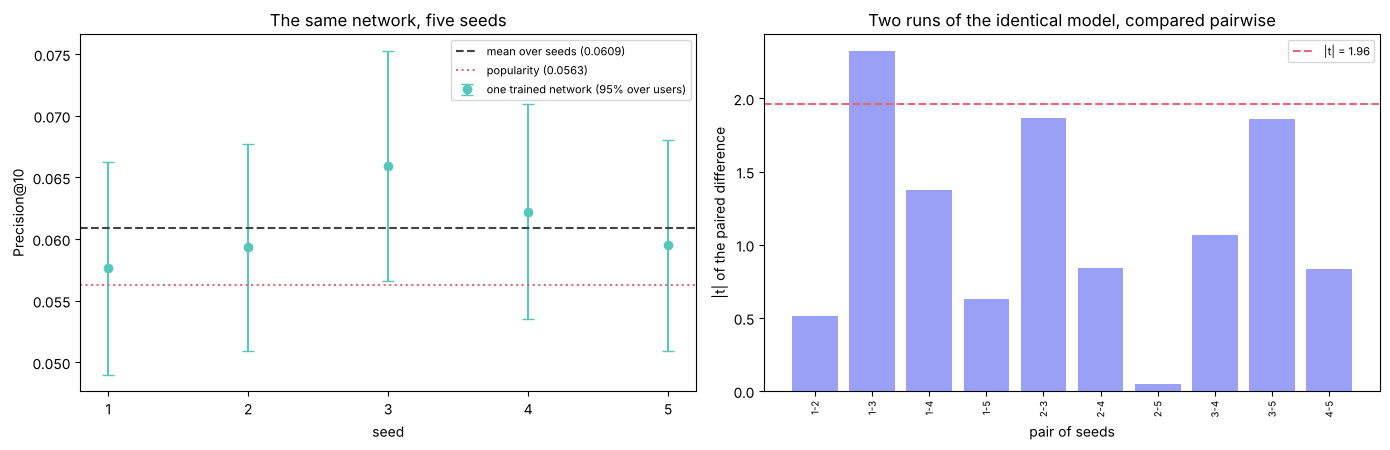

1 of the 10 pairs of seeds differ 'significantly' (|t| > 1.96) while being the very same model.


In [29]:
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 4.6))

left.errorbar(seed_table.index, seed_table["precision"], yerr=1.96 * seed_table["precision_se"],
              fmt="o", capsize=4, color="#56c8ba", label="one trained network (95% over users)")
left.axhline(spread.mean(), color="#444", ls="--", label=f"mean over seeds ({spread.mean():.4f})")
left.axhline(popularity["precision"], color="#e8647a", ls=":", label=f"popularity ({popularity['precision']:.4f})")
left.set(xlabel="seed", ylabel=f"Precision@{K}", title="The same network, five seeds")
left.set_xticks(list(seed_table.index))
left.legend(fontsize=8)

# How often do two seeds of the SAME model look significantly different?
pairs = [(a, b) for a, b in itertools.combinations(seed_table.index, 2)]
t_values = [paired_difference(seed_frames[a], seed_frames[b])["t"] for a, b in pairs]
right.bar([f"{a}-{b}" for a, b in pairs], np.abs(t_values), color="#9aa0f5")
right.axhline(1.96, color="#e8647a", ls="--", label="|t| = 1.96")
right.set(xlabel="pair of seeds", ylabel="|t| of the paired difference",
          title="Two runs of the identical model, compared pairwise")
right.tick_params(axis="x", labelrotation=90, labelsize=7)
right.legend(fontsize=8)
plt.tight_layout()
plt.show()

significant = sum(1 for t in t_values if abs(t) > 1.96)
print(f"{significant} of the {len(pairs)} pairs of seeds differ 'significantly' (|t| > 1.96) "
      "while being the very same model.")

> **Conclusion — the seed noise is smaller than the per-user noise, but not
> small enough to be ignored.**
>
> | seed | 1 | 2 | 3 | 4 | 5 |
> |---|---|---|---|---|---|
> | Precision@10 | 0.0576 | 0.0593 | 0.0659 | 0.0622 | 0.0595 |
>
> * Spread **between seeds**: standard deviation 0.0032, from 0.0576 to
>   0.0659 — a 14 % relative range for a model whose architecture, features,
>   data and hyper-parameters never changed.
> * Uncertainty **within one run**: the standard error over users is 0.0045,
>   so the 95 % interval of a single network (± 0.0088) comfortably contains
>   every other seed. The two noises are of the same order, the user one being
>   the larger here.
>
> **The trap this exposes.** Pairing per-user scores makes the test *more*
> sensitive, and that cuts both ways: among the ten pairs of seeds — ten
> comparisons of a model with *itself* — one comes out "significant" at
> |t| > 1.96. A paired t-test between two single training runs cannot tell a
> better architecture from a luckier initialisation.
>
> **What it means for the numbers above.** The network used in sections 5 to 8
> is seed 1, which happens to be the **worst** of the five (0.0576 against a
> seed mean of 0.0609). So:
>
> * the hybrid's advantage over the network (+0.0129, t = 4.03) is four times
>   the seed standard deviation — it survives, but part of it is seed luck, and
>   an honest statement of it is "between roughly +0.007 and +0.016";
> * the network's advantage over popularity (+0.0014, t = 0.29) was already
>   within the user noise; the seed mean (0.0609 against 0.0563) does not
>   rescue it either, since 0.0046 is barely more than one seed deviation.
>
> **The rule to take away:** compare *architectures* over several seeds and
> report the spread; compare *rankings produced by one fixed model* with
> paired per-user tests. Mixing the two — a paired test between two
> single-seed networks — is how one publishes noise.

---
**End of TP 05.**